# Refresher RP1: Magnetism from Currents

**Part:** Physics refresher · **Reading time:** ~30 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Complex numbers, rotations & cross products](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

An MRI scanner is, at its heart, a carefully arranged set of **wires carrying currents**. The 3 T main field, the gradient fields that encode position, and the RF field that tips the spins are all made by currents flowing through loops of wire. This refresher starts from school physics ("a current makes a magnetic field, a compass needle turns") and builds up exactly what you need to understand *why* the main magnet is a long superconducting solenoid and *how* a pair of loops can make either a uniform field or a linear gradient.

## Learning goals

1. Know what the magnetic field $\vec B$ is, its unit (tesla, gauss), and realistic field strengths from the Earth to an MRI scanner.
2. Use the right-hand rule and the formula for the field of a long straight wire.
3. Read the **Biot–Savart law** term by term and use it numerically.
4. Compute the field of a circular loop and of a solenoid; explain why a long solenoid gives a homogeneous field.
5. Use **superposition** to build a Helmholtz pair (uniform field) and a Maxwell pair (linear gradient), the ancestors of MRI magnet and gradient coils.
6. Estimate the current needed for a 3 T whole-body magnet, and explain why it must be superconducting.

## Symbols used in this refresher

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec B$, $B$ | magnetic flux density, "the magnetic field" (vector / its size) | T (tesla) | Earth ≈ 50 µT; MRI 1.5–7 T |
| $\vec H$ | magnetic field strength ("H-field") | A/m | we will hardly use it; $\vec B\approx\mu_0\vec H$ in tissue |
| $\vec M_{mat}$ | magnetization of a material (magnetic moment per volume) | A/m | only in the B-vs-H box |
| $\mu_0$ | vacuum permeability (constant of nature) | T m/A | $4\pi\times10^{-7}\approx1.257\times10^{-6}$ |
| $I_c$ | electric current (written $I$ in formulas of this notebook) | A | ⚠️ in spin physics $I$ is the spin number |
| $r$ | distance from a wire / from a current element | m | |
| $\vec r$, $\vec r\,'$ | observation point; position of a current element | m | |
| $d\vec l$ | short piece of wire, pointing along the current | m | |
| $d\vec B$ | field contribution of the piece $d\vec l$ | T | |
| $\hat{\mathbf e}$ | unit vector (length 1) from the current element to the observation point | – | |
| $R$ | radius of a current loop or solenoid | m | whole-body magnet bore ≈ 0.3–0.5 m radius |
| $z$ | position along the loop/solenoid axis (= MRI bore axis) | m | |
| $n$ | number of turns per metre of a solenoid | 1/m | |
| $N_{turns}$ | number of turns | – | |
| $L_{sol}$ | length of a solenoid | m | 1.2–1.8 m in whole-body MRI |
| $d$ | separation between two loops | m | Helmholtz $d=R$; Maxwell $d=\sqrt3 R$ |
| $G$ | gradient: rate of change of $B_z$ with position | T/m | MRI 20–80 mT/m |
| $\vec F$ | force | N | |
| $J$ | current density (current per cross-section area) | A/m² | copper ≈ 1–5 A/mm² |
| $\rho_{Cu}$ | resistivity of copper | Ω m | $1.7\times10^{-8}$ at room temperature |
| $P$ | electrical power (heat) | W | |
| $E_{mag}$ | stored magnetic energy | J | several MJ for a 3 T magnet |
| ppm | parts per million, $10^{-6}$ | – | homogeneity spec of MRI magnets |

> **⚠️ Common confusion:** In this notebook $T$ only appears as the unit **tesla**. Elsewhere in the series $T$ is temperature and $T_1, T_2$ are relaxation time constants. Likewise $I$ here is a current; in spin physics $I$ is the spin quantum number.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What is a magnetic field?

From school you know two facts:

* a **compass needle** turns to point along the magnetic field of the Earth or of a magnet;
* a wire carrying a current deflects a compass needle (Ørsted, 1820): **moving charges make magnetic fields**, and magnetic fields push on moving charges.

The **magnetic field** $\vec B$ is a vector field: at every point in space it has a size and a direction. Operationally it is defined by the force it exerts on a charge $q$ moving with velocity $\vec v$ (the magnetic part of the **Lorentz force**):

$$\vec F = q\,\vec v\times\vec B .$$

In words: the force is perpendicular both to the motion and to the field, and grows with charge, speed and field strength.
Where: $\vec F$ = force [N], $q$ = charge [C], $\vec v$ = velocity [m/s], $\times$ = cross product ([RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)), $\vec B$ = magnetic field [T].

From this, 1 tesla is the field in which a charge of 1 C moving at 1 m/s feels a force of 1 N: $1\,\mathrm T = 1\,\mathrm{N\,s/(C\,m)} = 1\,\mathrm{N/(A\,m)}$. The older unit **gauss** is still used for small fields and in safety signs: $1\,\mathrm T = 10\,000\,\mathrm G$ (the "5 gauss line" around a scanner = 0.5 mT).

**Field lines** are curves that are everywhere tangent to $\vec B$. Their density shows the field strength. Magnetic field lines never start or end: they always close on themselves (there are no magnetic "charges"). A compass needle lines up with the field lines.

<details><summary><b>📐 B versus H (optional, you can skip this)</b></summary>

Textbooks use two magnetic fields. $\vec B$ (flux density, tesla) is the one that exerts forces and that spins precess about. $\vec H$ (field strength, A/m) is a bookkeeping field that only counts the "free" currents in wires. They are related by

$$\vec B = \mu_0\left(\vec H + \vec M_{mat}\right),$$

where $\vec M_{mat}$ [A/m] is the magnetization of the material (its magnetic moment per volume) and $\mu_0 = 4\pi\times10^{-7}$ T m/A. In vacuum $\vec M_{mat}=0$, so $\vec B=\mu_0\vec H$. Tissue is only very weakly magnetic (susceptibility $\chi\approx-9\times10^{-6}$ for water), so $\vec B\approx\mu_0\vec H$ to within about 10 ppm. That 10 ppm matters for image distortions (see [In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb)), but for building coils it does not. **In this whole series "magnetic field" means $\vec B$, measured in tesla.**

</details>

### How big are magnetic fields?

The range of fields in and around MRI spans about 13 orders of magnitude, so we plot them on a logarithmic axis.

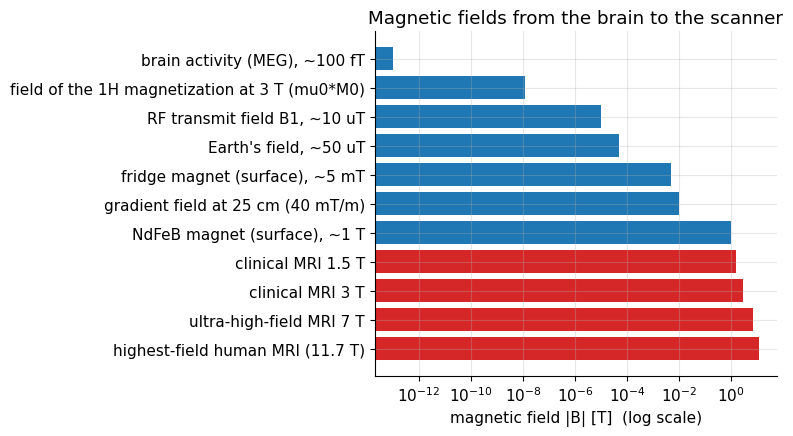

In [2]:
# Typical magnetic field magnitudes [T] (order-of-magnitude values)
fields = {
    "brain activity (MEG), ~100 fT":            1e-13,
    "field of the 1H magnetization at 3 T (mu0*M0)": 1.2e-8,
    "RF transmit field B1, ~10 uT":              1e-5,
    "Earth's field, ~50 uT":                     5e-5,
    "fridge magnet (surface), ~5 mT":            5e-3,
    "gradient field at 25 cm (40 mT/m)":         0.04 * 0.25,
    "NdFeB magnet (surface), ~1 T":              1.0,
    "clinical MRI 1.5 T":                        1.5,
    "clinical MRI 3 T":                          3.0,
    "ultra-high-field MRI 7 T":                  7.0,
    "highest-field human MRI (11.7 T)":          11.7,
}
names, vals = list(fields), np.array(list(fields.values()))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(names, vals, color=["C0"] * 7 + ["C3"] * 4)
ax.set_xscale("log")
ax.set_xlabel("magnetic field |B| [T]  (log scale)")
ax.invert_yaxis()
ax.set_title("Magnetic fields from the brain to the scanner")
plt.tight_layout(); plt.show()

The main field (red) is ~60 000 × the Earth's field, while the field made by the nuclei themselves (μ0M0, see [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)) is about a billion times smaller than $B_0$. We pick up that tiny field only because it oscillates at a frequency where nothing else in the room does ([RP2](../refreshers/RP2_Induction_and_RF.ipynb)).

## 2. The field of a long straight wire

A straight wire carrying current $I$ makes circular field lines around the wire. Their direction is given by the **right-hand rule**: point your right thumb along the (conventional, + to −) current, and your fingers curl in the direction of $\vec B$.

> **⚠️ Common confusion:** The original book says "left-hand rule" here. For conventional current (positive charges moving from + to −) the field direction around a wire or loop is given by the **right**-hand rule. (A "left-hand rule" exists in some school curricula, but it is either for electron flow or Fleming's rule for the *force* on a wire, a different question.)

The field strength at distance $r$ from a long straight wire is

$$B(r) = \frac{\mu_0 I}{2\pi r}.$$

In words: the field is proportional to the current and falls off as $1/r$ with distance from the wire.
Where: $B$ = field magnitude [T], $I$ = current [A], $r$ = perpendicular distance from the wire [m], $\mu_0 = 4\pi\times10^{-7}$ T m/A. The combination $\mu_0/2\pi = 2\times10^{-7}$ T m/A is easy to remember.

**Numbers:** 10 A (a kettle) at 1 cm gives $2\times10^{-7}\cdot 10/0.01 = 2\times10^{-4}$ T = 0.2 mT, four times the Earth's field. To reach 3 T at 1 cm you would need 150 000 A in a single wire. Clearly we need to *add up* the fields of many wires: that is what coils do.

## 3. The Biot–Savart law: the field of any current

For wires of arbitrary shape we chop the wire into tiny straight pieces and add up their contributions. The contribution of one piece is given by the **Biot–Savart law**:

$$d\vec B(\vec r) = \frac{\mu_0}{4\pi}\,\frac{I\, d\vec l\times\hat{\mathbf e}}{|\vec r-\vec r\,'|^2},\qquad \hat{\mathbf e}=\frac{\vec r-\vec r\,'}{|\vec r-\vec r\,'|}.$$

In words: a short piece of current-carrying wire makes a field that (i) is proportional to the current and the length of the piece, (ii) falls off as one over distance squared, and (iii) points perpendicular both to the wire piece and to the line joining the piece to the observation point.

Term by term:

| Term | Meaning |
|---|---|
| $\vec r$ | where we want to know the field (observation point) [m] |
| $\vec r\,'$ | where the little piece of wire sits [m] |
| $\vec r-\vec r\,'$ | arrow from the wire piece to the observation point; its length $\lvert\vec r-\vec r\,'\rvert$ is the distance [m] |
| $\hat{\mathbf e}$ | the same arrow scaled to length 1 (only the direction) |
| $I$ | current in the wire [A] |
| $d\vec l$ | the little piece of wire as a vector: length = piece length [m], direction = direction of current |
| $d\vec l\times\hat{\mathbf e}$ | cross product: perpendicular to both; its size is $dl\,\sin\alpha$, with $\alpha$ the angle between wire and line of sight. A piece "seen end-on" ($\alpha=0$) contributes nothing |
| $1/\lvert\vec r-\vec r\,'\rvert^2$ | inverse-square fall-off, like gravity or light from a lamp |
| $\mu_0/4\pi$ | conversion constant, $10^{-7}$ T m/A |
| $d\vec B$ | the field contribution of this piece [T] |

The total field is the sum (integral) over all pieces: $\vec B(\vec r)=\frac{\mu_0 I}{4\pi}\oint \frac{d\vec l\times(\vec r-\vec r\,')}{|\vec r-\vec r\,'|^3}$. (We merged $\hat{\mathbf e}/|\vec r-\vec r\,'|^2 = (\vec r-\vec r\,')/|\vec r-\vec r\,'|^3$.) The right-hand rule is built into the cross product.

<details><summary><b>📐 Derivation: straight wire from Biot–Savart (optional)</b></summary>

Put the wire on the $z$-axis, current in $+z$, and the observation point at distance $r$ on the $x$-axis. A piece at height $z'$ has $d\vec l = dz'\,\hat z$, distance $s=\sqrt{r^2+z'^2}$, and $|d\vec l\times\hat{\mathbf e}| = dz'\sin\alpha = dz'\, r/s$. All pieces give a field in the same ($+y$) direction, so we can add magnitudes:

$$B = \frac{\mu_0 I}{4\pi}\int_{-\infty}^{\infty}\frac{r\,dz'}{(r^2+z'^2)^{3/2}} = \frac{\mu_0 I}{4\pi}\cdot\frac{2}{r} = \frac{\mu_0 I}{2\pi r}.$$

(The integral $\int_{-\infty}^\infty r\,dz'/(r^2+z'^2)^{3/2} = 2/r$ follows with the substitution $z' = r\tan u$.)

</details>

### Demo: Biot–Savart by brute force

To see that the law really is "just add up the pieces", here is a 10-line implementation for a straight wire (`mri_tools.loop_coil_field` does exactly the same for a circle). We check it against $\mu_0 I/2\pi r$.

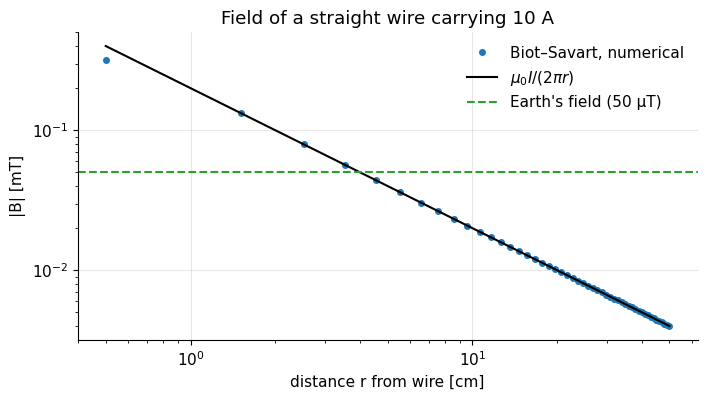

field direction at (x>0, 0, 0): [0. 1. 0.]  -> +y, as the right-hand rule says


In [3]:
def biot_savart_polyline(points, wire, current):
    """Field [T] at `points` (P,3) of a current [A] flowing along the polyline `wire` (S+1,3).
    Each straight segment is treated as one small current element I*dl located at its midpoint."""
    mid = 0.5 * (wire[1:] + wire[:-1])            # r' : positions of the pieces      (S,3)
    dl = wire[1:] - wire[:-1]                      # dl : the pieces as vectors        (S,3)
    Rv = points[:, None, :] - mid[None, :, :]      # r - r' for every point/piece pair (P,S,3)
    Rn = np.linalg.norm(Rv, axis=-1, keepdims=True)
    dB = mt.MU0 * current / (4 * np.pi) * np.cross(dl[None], Rv) / Rn**3
    return dB.sum(axis=1)                          # superposition: add all pieces

I = 10.0                                            # current [A]
wire = np.stack([np.zeros(4001), np.zeros(4001), np.linspace(-20, 20, 4001)], axis=-1)  # 40 m long wire on z-axis
r = np.linspace(0.005, 0.5, 50)                     # distances 5 mm ... 50 cm
pts = np.stack([r, np.zeros_like(r), np.zeros_like(r)], axis=-1)
B_num = biot_savart_polyline(pts, wire, I)

plt.loglog(r * 100, np.abs(B_num[:, 1]) * 1e3, "o", ms=4, label="Biot–Savart, numerical")
plt.loglog(r * 100, mt.MU0 * I / (2 * np.pi * r) * 1e3, "k-", label=r"$\mu_0 I/(2\pi r)$")
plt.axhline(50e-3, color="C2", ls="--", label="Earth's field (50 µT)")
plt.xlabel("distance r from wire [cm]"); plt.ylabel("|B| [mT]")
plt.title("Field of a straight wire carrying 10 A"); plt.legend(); plt.show()
print("field direction at (x>0, 0, 0):", np.round(B_num[0] / np.linalg.norm(B_num[0]), 3), " -> +y, as the right-hand rule says")

The numerical sum reproduces the $1/r$ law exactly (straight line of slope −1 on the log–log plot), and the field circles the wire in the right-hand sense. 10 A gives an Earth-strength field only about 4 cm from the wire.

## 4. A circular loop

Bend the wire into a circle of radius $R$. Now all pieces of the wire make fields that point in the **same** direction at the centre (right-hand rule: curl your fingers along the current, the thumb gives $\vec B$ through the loop). Biot–Savart on the loop axis gives

$$B_z(z) = \frac{\mu_0 I R^2}{2\,(R^2+z^2)^{3/2}},\qquad B_z(0)=\frac{\mu_0 I}{2R}.$$

In words: the field on the axis is strongest at the centre of the loop and falls off with distance $z$ from the loop plane, eventually like $1/z^3$ (a **dipole** field).
Where: $z$ = position along the axis measured from the loop plane [m], $R$ = loop radius [m], $I$ = current [A]. This is `mt.loop_field_on_axis(z, R, I)`.

<details><summary><b>📐 Derivation of the on-axis field (optional)</b></summary>

Every piece $d\vec l$ of the loop is perpendicular to the line to the axis point, so $|d\vec l\times\hat{\mathbf e}|=dl$, and the distance is $s=\sqrt{R^2+z^2}$. Each piece gives $dB = \frac{\mu_0 I}{4\pi}\frac{dl}{s^2}$, tilted from the axis. By symmetry the sideways parts cancel between opposite pieces; the axial part is a fraction $R/s$ of $dB$. Summing over the circumference ($\oint dl = 2\pi R$):

$$B_z = \frac{\mu_0 I}{4\pi}\,\frac{2\pi R}{s^2}\,\frac{R}{s} = \frac{\mu_0 I R^2}{2 (R^2+z^2)^{3/2}}.$$

For $z\gg R$: $B_z\approx \mu_0 I R^2/(2z^3) = \frac{\mu_0}{2\pi}\frac{m}{z^3}$, with $m = I\pi R^2$ the **magnetic moment** of the loop [A m²] — the same kind of quantity a nucleus has ([RP3](../refreshers/RP3_Precession_and_Torque.ipynb)).

</details>

The original book shows the loop field like this (more current → stronger field, same shape):

| ![Loop with small current](../images/loop_small_current.png) | ![Loop with big current](../images/loop_big_current.png) |
| :-: | :-: |
| Loop with a small current | Same loop, larger current: same field pattern, larger magnitude |

Let us compute the full field off the axis too, with `mt.loop_coil_field` (a numerical Biot–Savart sum over 200 straight segments). First a check on the axis:

In [4]:
R, I = 0.10, 1.0                                   # loop radius 10 cm, current 1 A
z = np.linspace(-0.4, 0.4, 81)
axis_pts = np.stack([np.zeros_like(z), np.zeros_like(z), z], axis=-1)
Bz_num = mt.loop_coil_field(axis_pts, radius=R, current=I)[:, 2]
Bz_ana = mt.loop_field_on_axis(z, R, I)
print(f"max relative difference numerical vs analytic: {np.max(np.abs(Bz_num - Bz_ana) / Bz_ana):.1e}")
print(f"field at the centre: {Bz_ana[40] * 1e6:.2f} uT per ampere   (mu0/(2R) = {mt.MU0 / (2 * R) * 1e6:.2f} uT/A)")

max relative difference numerical vs analytic: 2.1e-04
field at the centre: 6.28 uT per ampere   (mu0/(2R) = 6.28 uT/A)


Now a map of the field in the $x$–$z$ plane (a cut through the loop, which is seen edge-on as two dots). Colour = $|\vec B|$ on a log scale, lines = field lines.

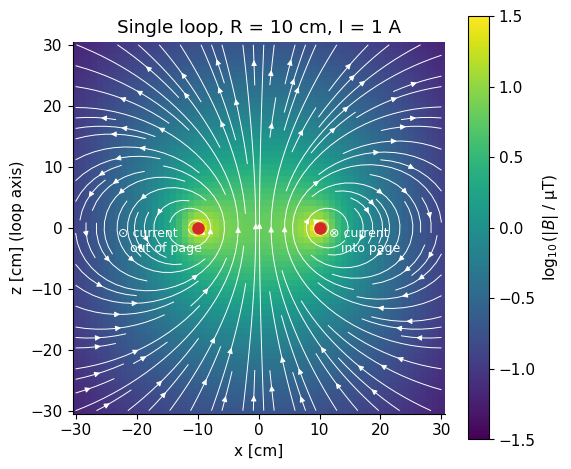

In [5]:
x = np.linspace(-0.3, 0.3, 61)
zz = np.linspace(-0.3, 0.3, 61)
X, Z = np.meshgrid(x, zz)
grid = np.stack([X, np.zeros_like(X), Z], axis=-1)        # points in the y = 0 plane
B = mt.loop_coil_field(grid, radius=R, current=I)
Bmag = np.linalg.norm(B, axis=-1)

fig, ax = plt.subplots(figsize=(6, 5.5))
pc = ax.pcolormesh(X * 100, Z * 100, np.log10(Bmag * 1e6), cmap="viridis", shading="auto", vmin=-1.5, vmax=1.5)
ax.streamplot(X * 100, Z * 100, B[..., 0], B[..., 2], color="w", density=1.2, linewidth=0.7, arrowsize=0.8)
ax.plot([-R * 100, R * 100], [0, 0], "o", color="C3", ms=8)
# loop current runs counter-clockwise seen from +z: at x=+R it flows along +y = INTO the page here
ax.text(R * 100 + 1.5, -4, "⊗ current\n   into page", color="w", fontsize=9)
ax.text(-R * 100 - 13, -4, "⊙ current\n   out of page", color="w", fontsize=9)
ax.set_xlabel("x [cm]"); ax.set_ylabel("z [cm] (loop axis)"); ax.set_aspect("equal")
ax.set_title("Single loop, R = 10 cm, I = 1 A"); ax.grid(False)
plt.colorbar(pc, ax=ax, label=r"$\log_{10}(|B|$ / µT$)$")
plt.show()

The field lines thread through the loop and close around the wire; the field is strong and fairly uniform only very close to the loop centre and dies off within a couple of radii. This "dipole" pattern is also what each nucleus makes, and what a small receive-coil element is sensitive to ([RP2](../refreshers/RP2_Induction_and_RF.ipynb)).

## 5. Superposition and the solenoid

**Superposition:** the field of several currents is the **vector sum** of their individual fields. (This holds because the equations of magnetism are linear in the current; it is exactly the "add up the pieces" step of Biot–Savart.)

A **solenoid** is many loops stacked along an axis. Inside a long solenoid the fields of the individual loops add up to a field that is strong, parallel to the axis and nearly uniform:

$$B = \mu_0\, n\, I \qquad (n = N_{turns}/L_{sol}).$$

In words: the field inside depends only on the number of ampere-turns per metre, not on the radius.
Where: $n$ = turns per metre [1/m], $I$ = current per turn [A], $N_{turns}$ = number of turns, $L_{sol}$ = solenoid length [m]. Valid deep inside a solenoid much longer than its radius.

<details><summary><b>📐 Derivation from the loop formula (optional)</b></summary>

A thin slice $dz'$ of the solenoid at position $z'$ carries $n\,I\,dz'$ ampere-turns and acts like a loop. On the axis at $z$:

$$B_z(z) = \int_{-L_{sol}/2}^{L_{sol}/2} \frac{\mu_0 n I R^2\,dz'}{2(R^2+(z-z')^2)^{3/2}} = \frac{\mu_0 n I}{2}\left[\frac{z+L_{sol}/2}{\sqrt{R^2+(z+L_{sol}/2)^2}}-\frac{z-L_{sol}/2}{\sqrt{R^2+(z-L_{sol}/2)^2}}\right].$$

For $L_{sol}\gg R$ and $z$ near the middle, both fractions approach $\pm1$, giving $B=\mu_0 nI$. At the very ends the bracket is ≈ 1, i.e. the field drops to **half**.

</details>

![Solenoid](../images/solenoid_small_current.png)

*Solenoid (from the original book): many loops together create a large region of strong, parallel field inside.*

Let us build solenoids numerically from individual loops using superposition, and compare a short and a long one with the same number of turns per metre.

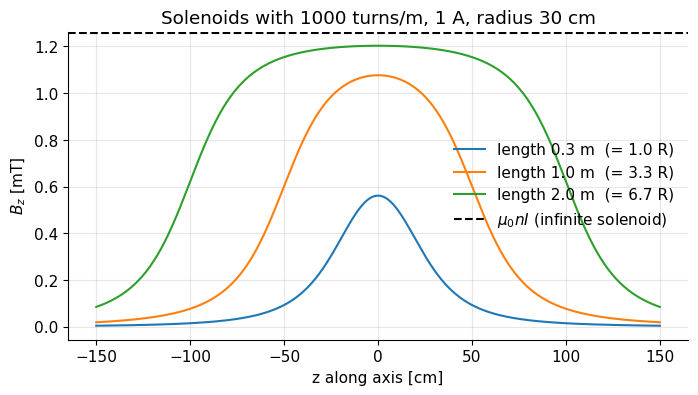

In [6]:
def solenoid_on_axis(z, R, length, n_turns, current):
    """On-axis Bz [T] of a solenoid, built by superposition of n_turns loops (mt.loop_field_on_axis)."""
    z_loops = np.linspace(-length / 2, length / 2, n_turns)
    return sum(mt.loop_field_on_axis(z - zl, R, current) for zl in z_loops)

R, I, n = 0.3, 1.0, 1000                 # radius 30 cm, 1 A, 1000 turns per metre
z = np.linspace(-1.5, 1.5, 601)
plt.figure(figsize=(8, 4))
for length in [0.3, 1.0, 2.0]:
    Bz = solenoid_on_axis(z, R, length, int(n * length), I)
    plt.plot(z * 100, Bz * 1e3, label=f"length {length:.1f} m  (= {length / R:.1f} R)")
plt.axhline(mt.MU0 * n * I * 1e3, color="k", ls="--", label=r"$\mu_0 n I$ (infinite solenoid)")
plt.xlabel("z along axis [cm]"); plt.ylabel(r"$B_z$ [mT]")
plt.title("Solenoids with 1000 turns/m, 1 A, radius 30 cm"); plt.legend(); plt.show()

The long solenoid has a flat plateau at $\mu_0 n I$ (1.26 mT per A at 1000 turns/m); the short one never reaches it. This is why **MRI main magnets are long solenoids**: a long coil gives a large region of strong, *homogeneous*, axial field — that axis is what we call $z$.

But "flat" for an MRI magnet means a few **ppm** (parts per million) over a 40–50 cm sphere. How flat is a simple solenoid?

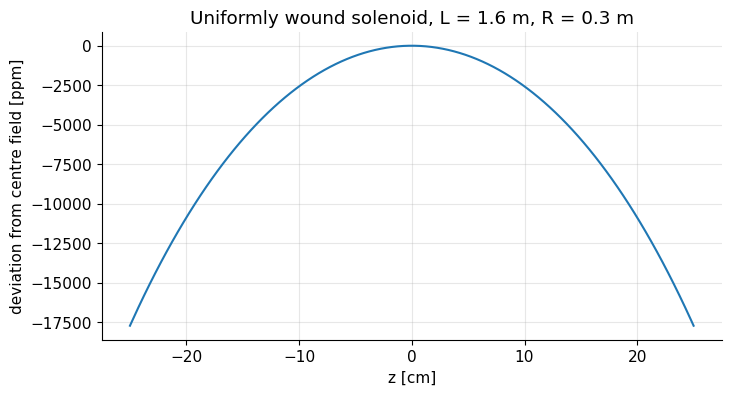

deviation at z = +-20 cm: -10872 ppm


In [7]:
L_sol = 1.6                                    # a typical whole-body magnet length [m]
z = np.linspace(-0.25, 0.25, 201)              # +-25 cm around the centre
Bz = solenoid_on_axis(z, R, L_sol, int(n * L_sol), I)
ppm = (Bz / Bz[100] - 1) * 1e6
plt.plot(z * 100, ppm)
plt.xlabel("z [cm]"); plt.ylabel("deviation from centre field [ppm]")
plt.title(f"Uniformly wound solenoid, L = {L_sol} m, R = {R} m")
plt.show()
print(f"deviation at z = +-20 cm: {ppm[np.argmin(abs(z - 0.2))]:.0f} ppm")

A uniformly wound solenoid of realistic proportions is "only" homogeneous to about 1 % (≈ 10 000 ppm) over ±20 cm — some 10 000 × worse than needed. In MRI terms, 10 000 ppm at 3 T would shift the resonance frequency by 1.3 MHz across the head and wreck the image.

> **🔧 Engineering reality:** Real MRI magnets are not one uniform winding. They consist of ~6–10 coil blocks with different numbers of turns (and some with reversed current) whose positions are optimized so that the error terms of the field expansion cancel up to high order. What remains (plus the disturbance by the patient and the building steel) is corrected by **shimming**: passive iron pieces and active shim coils. Specs are quoted as e.g. "< 1 ppm over 40 cm DSV" (diameter of spherical volume). Details in [Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb).

## 6. Numbers: what does it take to make 3 T?

For a solenoid, $B=\mu_0 nI$, so the required **ampere-turns per metre** is $nI = B/\mu_0$. Let us estimate what a 3 T, 1 m bore (radius 0.5 m), 1.6 m long magnet needs, first with copper wire and then with a superconductor.

In [8]:
B0 = 3.0                         # target field [T]
L_sol, R_bore = 1.6, 0.5         # solenoid length and radius [m]
nI = B0 / mt.MU0                 # ampere-turns per metre needed
print(f"required n*I = {nI:.2e} A-turns per metre  -> {nI * L_sol:.2e} A-turns in total")

# --- Option 1: copper at a (generous, water-cooled) current density of 4 A/mm^2 ---
J_cu = 4e6                       # current density [A/m^2]
rho_cu = 1.7e-8                  # resistivity [Ohm m]
thick = nI / J_cu                # winding thickness needed so that J*thickness = n*I  [m]
vol = 2 * np.pi * (R_bore + thick / 2) * thick * L_sol   # copper volume [m^3]
P = rho_cu * J_cu**2 * vol       # ohmic heat P = rho J^2 * volume [W]
print(f"copper: winding {thick * 100:.0f} cm thick, {vol * 8960 / 1000:.0f} tonnes of Cu, "
      f"dissipating {P / 1e6:.1f} MW of heat - continuously")

# --- Option 2: superconductor (NbTi at 4.2 K), typical operating current ~ 400 A ---
I_op = 400.0
turns_per_m = nI / I_op
wire_length = turns_per_m * L_sol * 2 * np.pi * R_bore
print(f"superconductor: {turns_per_m:.0f} turns/m at {I_op:.0f} A -> ~{wire_length / 1000:.0f} km of wire, "
      f"0 W ohmic loss")

# Stored magnetic energy: energy density B^2/(2 mu0) times the (inner) volume
E_mag = B0**2 / (2 * mt.MU0) * np.pi * R_bore**2 * L_sol
print(f"stored energy in the bore ~ {E_mag / 1e6:.0f} MJ (energy density {B0**2 / (2 * mt.MU0) / 1e6:.1f} MJ/m^3)")

required n*I = 2.39e+06 A-turns per metre  -> 3.82e+06 A-turns in total
copper: winding 60 cm thick, 43 tonnes of Cu, dissipating 1.3 MW of heat - continuously
superconductor: 5968 turns/m at 400 A -> ~30 km of wire, 0 W ohmic loss
stored energy in the bore ~ 4 MJ (energy density 3.6 MJ/m^3)


A copper 3 T whole-body magnet would be a metre-thick, tens-of-tonnes block of copper burning megawatts — a power station's worth of heat, 24/7. That is why:

* **Resistive** magnets are limited to about 0.2–0.5 T (and permanent-magnet systems to ≈ 0.3–0.5 T).
* Clinical 1.5/3/7 T magnets are **superconducting**: niobium–titanium (NbTi) wire cooled by liquid helium to 4.2 K (−269 °C) has zero resistance. Once the current is ramped up, the coil is closed on itself ("persistent mode") and the current circulates for years without a power supply.
* The magnet stores **megajoules** of energy (our crude estimate counts only the bore; the real figure, including the field inside the windings, is of similar order). If the superconductor warms up locally it becomes resistive, this energy turns into heat and boils off helium: a **quench**.

> **🔧 Engineering reality:** The superconductor only stays superconducting below a critical temperature, current density *and* field. NbTi works up to ~9–10 T at 4.2 K, which is why 7 T is routine but 11.7 T needs extra-cold (1.8 K superfluid helium) magnets and very-high-field systems use Nb₃Sn. Cost, weight (a 3 T magnet weighs ~5–10 t), helium supply and the **fringe field** outside the bore (reduced by "active shielding" coils with reversed current) are all covered in [Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb).

## 7. Two loops: uniform field (Helmholtz) or gradient (Maxwell)

Superposition becomes really powerful when we choose *where* to put loops and *which way* the current flows. Take two coaxial loops of radius $R$ at $z=\pm d/2$:

* **Helmholtz pair:** currents in the **same** direction, separation $d = R$. The fields add, and the field near the centre is unusually flat.
* **Maxwell pair (anti-Helmholtz):** currents in **opposite** directions, separation $d=\sqrt3\,R$. The fields cancel at the centre, and $B_z$ changes **linearly** with $z$: a gradient $G = \partial B_z/\partial z$ [T/m].

<details><summary><b>📐 Why exactly d = R and d = √3 R? (optional)</b></summary>

Write the on-axis field of one loop as $B_1(z) = \frac{\mu_0 I R^2}{2}f(z)$ with $f(z)=(R^2+z^2)^{-3/2}$, and put the loops at $z=\pm a$ ($a=d/2$). Expand around the centre with a Taylor series.

*Same currents:* $B(z)\propto f(z-a)+f(z+a)$ is an even function of $z$, so all odd powers of $z$ vanish. The first error term is $\propto z^2 f''(a)$. Since $f''(z) = 3(4z^2-R^2)(R^2+z^2)^{-7/2}$, it vanishes for $a=R/2$, i.e. $d=R$. The first non-zero error is then $\propto z^4$: very flat.

*Opposite currents:* $B(z)\propto f(z-a)-f(z+a)$ is odd: $B(z) = G z + c_3 z^3 + \dots$. The cubic error term $\propto f'''(a)$, and $f'''(z) = -15z(4z^2-3R^2)(R^2+z^2)^{-9/2}$ vanishes for $a=\frac{\sqrt3}{2}R$, i.e. $d=\sqrt3R$. Then $B$ is linear in $z$ up to a $z^5$ error. Differentiating the two loop fields at $z=0$ gives the gradient

$$G = \frac{3\mu_0 I R^2 a}{(R^2+a^2)^{5/2}} \overset{a=\sqrt3 R/2}{=} \approx 0.64\,\frac{\mu_0 I}{R^2}.$$

</details>

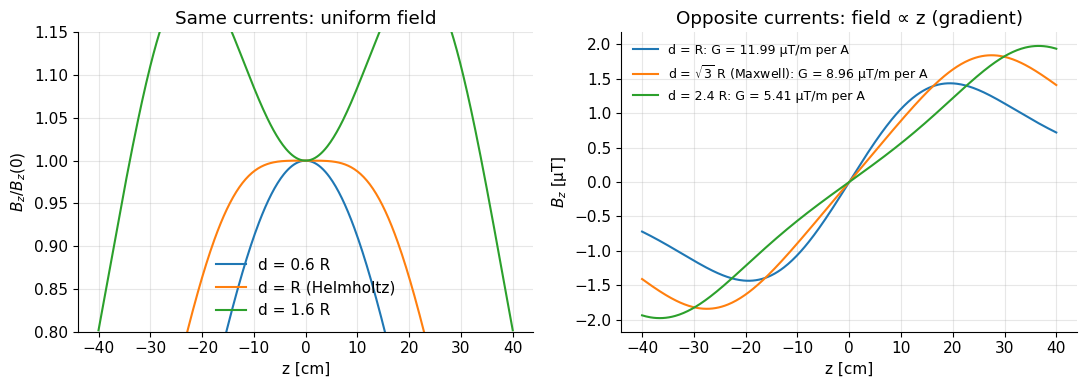

In [9]:
R, I = 0.3, 1.0                                  # loop radius 30 cm, 1 A
z = np.linspace(-0.4, 0.4, 401)
axis_pts = np.stack([np.zeros_like(z), np.zeros_like(z), z], axis=-1)

def pair_field(points, d, sign):
    """Two coaxial loops at z = +-d/2; sign=+1 same current direction, sign=-1 opposite."""
    return (mt.loop_coil_field(points, R, I, center=(0, 0, +d / 2))
            + sign * mt.loop_coil_field(points, R, I, center=(0, 0, -d / 2)))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for d, lab in [(0.6 * R, "d = 0.6 R"), (R, "d = R (Helmholtz)"), (1.6 * R, "d = 1.6 R")]:
    Bz = pair_field(axis_pts, d, +1)[:, 2]
    axs[0].plot(z * 100, Bz / Bz[200], label=lab)
axs[0].set_ylim(0.8, 1.15); axs[0].set_xlabel("z [cm]"); axs[0].set_ylabel(r"$B_z/B_z(0)$")
axs[0].set_title("Same currents: uniform field"); axs[0].legend()

for d, lab in [(R, "d = R"), (np.sqrt(3) * R, r"d = $\sqrt{3}$ R (Maxwell)"), (2.4 * R, "d = 2.4 R")]:
    Bz = pair_field(axis_pts, d, -1)[:, 2]
    G0 = np.gradient(Bz, z)[200]                       # gradient at the centre [T/m]
    axs[1].plot(z * 100, Bz * 1e6, label=f"{lab}: G = {G0 * 1e6:.2f} µT/m per A")
axs[1].set_xlabel("z [cm]"); axs[1].set_ylabel(r"$B_z$ [µT]")
axs[1].set_title("Opposite currents: field ∝ z (gradient)"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

Left: with $d=R$ the curve is flattest at the centre (closer loops give a bump, wider ones a dip). Right: with opposite currents the field crosses zero at the centre and is positive on one side, negative on the other; for $d=\sqrt3R$ it is a straight line over the widest range. Now the same two configurations as field maps:

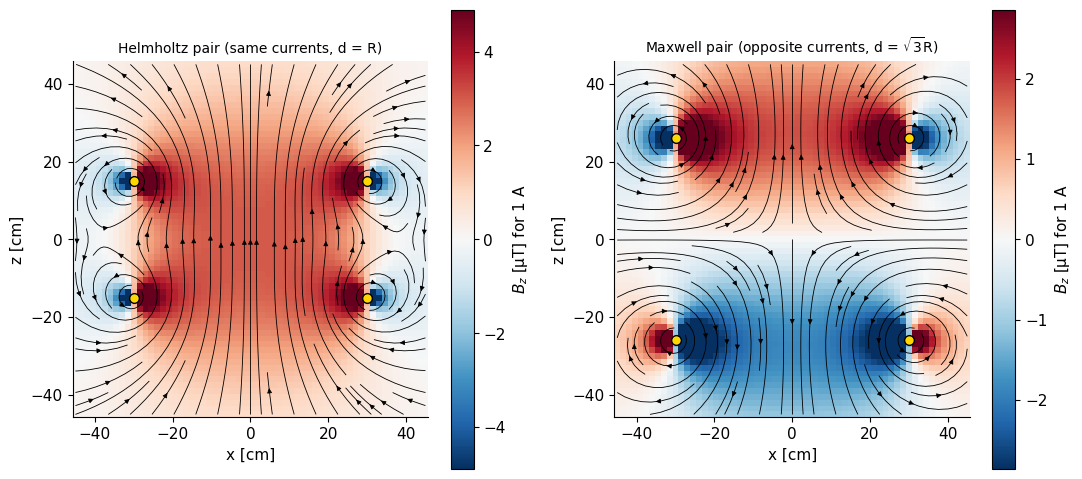

In [10]:
x = np.linspace(-0.45, 0.45, 61)
zz = np.linspace(-0.45, 0.45, 61)
X, Z = np.meshgrid(x, zz)
grid = np.stack([X, np.zeros_like(X), Z], axis=-1)

fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, (d, sign, title) in zip(axs, [(R, +1, "Helmholtz pair (same currents, d = R)"),
                                      (np.sqrt(3) * R, -1, r"Maxwell pair (opposite currents, d = $\sqrt{3}$R)")]):
    B = pair_field(grid, d, sign)
    Bz = B[..., 2] * 1e6                                           # µT
    inner = (np.abs(Z) < 0.2) & (np.abs(X) < 0.2)                  # colour scale from the central region
    lim = 1.3 * np.abs(Bz[inner]).max()
    pc = ax.pcolormesh(X * 100, Z * 100, Bz, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.streamplot(X * 100, Z * 100, B[..., 0], B[..., 2], color="k", density=1.1, linewidth=0.6, arrowsize=0.7)
    for zc in (+d / 2, -d / 2):
        ax.plot([-R * 100, R * 100], [zc * 100] * 2, "o", color="gold", mec="k", ms=7)
    ax.set_aspect("equal"); ax.grid(False); ax.set_title(title, fontsize=10)
    ax.set_xlabel("x [cm]"); ax.set_ylabel("z [cm]")
    plt.colorbar(pc, ax=ax, label=r"$B_z$ [µT] for 1 A")
plt.tight_layout(); plt.show()

(Colours are clipped to the range in the central region; near the wires the field is much stronger.) Left: a big region in the middle with the same colour (uniform $B_z$) — the principle behind every magnet that needs a homogeneous field. Right: $B_z$ goes from blue (negative) to red (positive) along $z$, with almost horizontal colour bands near the centre: $B_z \approx G\,z$, a **linear gradient**.

> **🧭 Intuition:** In MRI the gradient field is *added* to the big $B_0$: $B_z(\vec r) = B_0 + G z$. The Maxwell pair does not need to fight $B_0$; it only tilts it a little, by ~40 mT/m × 0.2 m = 8 mT out of 3 T. Because resonance frequency ∝ field, this tilt makes frequency depend on position — the basis of imaging ([Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb)).

How much current does a gradient coil need? For the Maxwell pair $G\approx0.64\,\mu_0 I/R^2$:

In [11]:
G_target = 40e-3          # 40 mT/m, a typical clinical gradient strength [T/m]
R_grad = 0.35             # gradient coil radius [m]
I_needed = G_target * R_grad**2 / (0.641 * mt.MU0)
print(f"Maxwell pair, R = {R_grad} m: {I_needed:.0f} ampere-turns per loop for {G_target * 1e3:.0f} mT/m")
print(f"with a 600 A gradient amplifier -> about {I_needed / 600:.0f} turns per loop")

Maxwell pair, R = 0.35 m: 6083 ampere-turns per loop for 40 mT/m
with a 600 A gradient amplifier -> about 10 turns per loop


Thousands of ampere-turns, switched on and off in ~0.2 ms: that is why gradient amplifiers are kilovolt, hundreds-of-ampere power electronics, and why gradients are loud (next box).

> **🔧 Engineering reality:** Real z-gradient coils are distributed windings (optimized by computer, "target-field" or "stream-function" design) rather than two thin loops; the x- and y-gradient coils (which must create $\partial B_z/\partial x$ in a bore along $z$) are "saddle" or "fingerprint" shaped. Gradient coils sit inside the 3 T field, so every current element feels the **Lorentz force** $\vec F = I\,d\vec l\times\vec B_0$: with ~600 A in 3 T that is $IB\approx$ 1800 N (the weight of ~180 kg) per metre of wire, switched on and off at kHz rates. The coil vibrates like a loudspeaker → the famous 100+ dB(A) noise. See [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb).

### 🎛️ Try it yourself

Change the separation and the current direction of the two loops and watch the axial profile. (Needs a live kernel; the static plots above show the default cases.)

In [12]:
try:
    from ipywidgets import interact, FloatSlider, Dropdown
    def _pair(d_over_R=1.0, currents="same"):
        sgn = +1 if currents == "same" else -1
        Bz = pair_field(axis_pts, d_over_R * R, sgn)[:, 2] * 1e6
        plt.figure(figsize=(7, 3.5)); plt.plot(z * 100, Bz)
        plt.xlabel("z [cm]"); plt.ylabel(r"$B_z$ [µT] per A"); plt.title(f"d = {d_over_R:.2f} R, {currents} currents")
        plt.show()
    interact(_pair, d_over_R=FloatSlider(value=1.0, min=0.2, max=3.0, step=0.05), currents=Dropdown(options=["same", "opposite"]))
except ImportError:
    print("ipywidgets not available - use the static plots above.")

interactive(children=(FloatSlider(value=1.0, description='d_over_R', max=3.0, min=0.2, step=0.05), Dropdown(de…

## Where this shows up in MRI

| Concept from this refresher | Where it is used |
|---|---|
| Tesla, field strengths, $\vec B$ along $z$ | [MRI System](../pass2_deep_dive/B1_MRI_System.ipynb), [Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| Long solenoid → homogeneous $B_0$; ppm homogeneity; superconductors, stored energy, quench, fringe field | [Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) |
| Superposition, Maxwell pair → linear gradient $G$; current per mT/m; Lorentz force and noise | [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb), [Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| Loop field (dipole pattern), field per ampere of a coil | [RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb), [Induction & RF refresher](../refreshers/RP2_Induction_and_RF.ipynb) |
| Projectile forces near the magnet, 5-gauss line | [MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) |

## Key takeaways

* The magnetic field $\vec B$ is measured in tesla (1 T = 10 000 G). Earth ≈ 50 µT; MRI 1.5–7 T.
* Currents make magnetic fields; the direction follows the **right-hand rule**; a long wire gives $B=\mu_0I/(2\pi r)$.
* The **Biot–Savart law** says: each piece of wire contributes $\frac{\mu_0}{4\pi}\frac{I\,d\vec l\times\hat{\mathbf e}}{r^2}$, and fields simply **add** (superposition).
* A loop gives $\mu_0 I/(2R)$ at its centre and a dipole pattern outside; a long solenoid gives a uniform $B=\mu_0 nI$ inside → MRI magnets are long solenoids (refined with extra coil blocks and shims for ppm homogeneity).
* 3 T in a whole-body bore needs ~$2.4\times10^6$ ampere-turns per metre: impossible with copper (MW of heat), routine with superconductors at 4 K.
* Two loops with **same** currents at $d=R$ (Helmholtz) give a uniform field; with **opposite** currents at $d=\sqrt3R$ (Maxwell) give a linear gradient — the idea behind gradient coils.

## Check your understanding

1. A long straight wire carries 100 A. How far from the wire does its field equal the Earth's field (50 µT)?

<details><summary>Answer</summary>

$r=\mu_0 I/(2\pi B) = 2\times10^{-7}\cdot100/(5\times10^{-5}) = 0.4$ m. So power cables can disturb compasses (and very sensitive MRI siting measurements) at tens of cm.

</details>

2. In the Biot–Savart law, why does a wire piece that points straight at the observation point contribute no field there?

<details><summary>Answer</summary>

The contribution contains the cross product $d\vec l\times\hat{\mathbf e}$, whose size is $dl\sin\alpha$. If the wire piece points along the line of sight, $\alpha=0$ and $\sin\alpha=0$.

</details>

3. You double the length of a long solenoid while keeping the total number of turns and the current fixed. What happens to the field in the middle?

<details><summary>Answer</summary>

$B=\mu_0 nI$ with $n=N_{turns}/L_{sol}$: doubling $L_{sol}$ halves $n$ and therefore halves the field (as long as the solenoid is still long compared with its radius).

</details>

4. Why can't we simply use a uniformly wound solenoid as an MRI magnet, and what do manufacturers do instead?

<details><summary>Answer</summary>

Its field over a ±20 cm region varies by about 1 % (~10 000 ppm), while MRI needs about 1 ppm. Manufacturers use several coil blocks with optimized positions/turns (some with reversed current) to cancel the low-order error terms, plus passive and active shimming.

</details>

5. Two identical coaxial loops carry opposite currents. What is the field exactly midway between them, and what is it useful for?

<details><summary>Answer</summary>

By symmetry the two contributions cancel, so $B_z=0$ at the midpoint, but $B_z$ grows linearly with $z$ on either side (with opposite signs). Added to $B_0$, this makes $B_z = B_0+Gz$: a z-gradient for spatial encoding. Separation $d=\sqrt3R$ makes it most linear (Maxwell pair).

</details>

6. Estimate the ohmic power of a 1.5 T copper magnet of the same geometry as in section 6. (Hint: how do $nI$, the winding thickness and $P$ scale with $B$ at fixed current density?)

<details><summary>Answer</summary>

At fixed $J$, the needed $nI\propto B$, so the winding thickness $\propto B$ and the copper volume roughly $\propto B$ (a bit less, because a thinner winding also has a smaller mean radius); $P=\rho J^2\cdot\text{volume}$. Halving the field therefore cuts the power to a bit less than half: about 0.5 MW (rerun the cell with `B0 = 1.5`). Resistive magnets only make sense up to a few tenths of a tesla.

</details>

---
*New refresher written for this adaptation; it expands the short "Loop currents and magnetic fields" section of P. Larson, "Principles of MRI" (MIT License), chapter "Magnetic Fields in MRI" (original images reused). Corrected: the field direction follows the right-hand (not left-hand) rule for conventional current.*

*References:* D. J. Griffiths, *Introduction to Electrodynamics* (Cambridge Univ. Press), ch. 5 (Biot–Savart, solenoid) · E. M. Purcell & D. J. Morin, *Electricity and Magnetism* (Cambridge Univ. Press) · D. W. McRobbie et al., *MRI from Picture to Proton* (Cambridge Univ. Press), chapter on MR hardware · R. W. Brown et al., *Magnetic Resonance Imaging: Physical Principles and Sequence Design*, 2nd ed. (Wiley), chapters on magnet and gradient design.